# NATS: aircraft queues, central scheduling and energy safety
This notebook retains the 16-section project structure and adds **a binary energy dispatch gate**. Aircraft continue to fly between configurable vertiports, queue for one shared pad, charge, serve passengers and change assignments. Both capacity studies remain: increasing demand at fixed fleet and reducing fleet at fixed demand.

An accepted departure meets the configured mission, reserve, landing-delay allowance, onward charging-access and forecast charger-wait conditions. This is a model decision, not a certification of complete aviation safety. Actual airborne queue waiting now uses energy. A run stops if a waiting aircraft reaches its protected reserve.

M/M/1/K remains a local approximation for the operational aircraft queue. Exact theory is tested with Poisson input to the same queue class; the network has schedules, finite fleets, energy gates, reservations and retries. The files include executed outputs, a browser-readable copy and neutral technical documentation.

## 1. Imports and file roles
`model.py` connects aircraft, flights, battery, passengers and scheduling. `queues.py` implements the actual aircraft pad queues used by that model. `results.py` measures recorded events; `mm1k.py` contains exact formulas, Markov transient probabilities and a controlled Poisson-input test of that same queue. `experiments.py` runs repeated scenarios; `plots.py` draws results.

The notebook is the entry point. Imports define classes and functions; `Simulation(config).run()` advances the operating network. `safety.py` contains the new dispatch policy and charging forecast.

In [1]:
from dataclasses import replace
from pathlib import Path
import json, math, unittest, io
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML, SVG
from model import ScenarioConfig, Simulation, example_config
from results import measurements, audit
from mm1k import theory, simulate, transient
from experiments import run_all, save_results, load_results, interval
import plots
%matplotlib inline
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

def table(rows, keys):
    import html
    def fmt(x):
        return f'{x:.3f}' if isinstance(x, (float, np.floating)) else str(x)
    header = ''.join('<th>'+html.escape(k)+'</th>' for k in keys)
    body = ''.join('<tr>'+''.join('<td>'+html.escape(fmt(row.get(k, '')) )+'</td>' for k in keys)+'</tr>' for row in rows)
    display(HTML('<table><thead><tr>'+header+'</tr></thead><tbody>'+body+'</tbody></table>'))
print('Imports ready. No simulation has run yet.')

Imports ready. No simulation has run yet.


Matplotlib is building the font cache; this may take a moment.


## 2. One editable configuration and the evidence behind it
The example has four hypothetical ports A–D, eight identical four-seat aircraft and four stands at each port. A has two chargers, C one, B and D none. Each directed route is 30 km. This is a schematic network, not a geographic or commercially calibrated UK system.

Later cells use the configuration below. Route dictionaries use keys such as `('A', 'C')`. `demand_per_hour` overrides the uniform total demand; `service_intervals_min` overrides the default timetable on particular routes. `initial_counts` controls aircraft placement, otherwise allocation is automatic.

| Input | Value used | Evidence / interpretation |
|---|---:|---|
| Passenger seats | 4, pilot excluded | [Archer Q3 2022 letter, p.5](https://www.sec.gov/Archives/edgar/data/1824502/000162828022029481/q32022exhibit991.htm): pilot plus four; historical design target |
| Cruise speed | 200 km/h | Illustrative scenario value. **Not an Archer measured specification** |
| Pad departure / arrival service | Exponential, mean 1 min each | [NASA 2020 study, Table 1 p.9](https://ntrs.nasa.gov/api/citations/20205001421/downloads/AIAA_Vertiport_Analysis_final_20200507.pdf?attachment=true): research assumptions of 60 s each; **the exponential distribution is an additional assumption** |
| Taxi transfers | 1 min each way | Same NASA table assumes 120 s combined; equal split is a project assumption |
| Boarding / unloading | 1 min per passenger each | Same NASA table; research handling assumption, not measured eVTOL turnaround |
| Charging comparison | Around 10 min after a 20-mile flight | Archer letter p.5 footnote 3: historical target, **not** full-battery recharge or demonstrated repeated-mission performance |
| Battery / power / energy | 100 kWh; 120 kW; 8 kWh vertical + 0.4 kWh/km | **Editable synthetic energy model**. A 30 km flight uses 20 kWh; replacing that energy takes 10 min at 120 kW and efficiency 1. This is arithmetic consistency, not data validation |
| Reserve / charge policy | 15% reserve, trigger 60%, target 90% | Illustrative modelling choices, not certified operational limits |
| Demand / timetable | 36 passengers/h total; 30 min per directed route | Hypothetical demand and offered service, with staggered route phases |
| Service targets | 95% complete; 95% depart within 60 min | Illustrative project criteria, not regulations |

No US, UK or EU operating regulation is asserted as an implemented constraint. Airspace, weather, certification, reserves mandated by regulators, and interactions with conventional aviation need a later model and appropriate sources. See `SOURCES_AND_ASSUMPTIONS.txt` for the exact claim-to-link mapping.

Each port has **one** shared pad, K=4 aircraft including service, and four separate parking stands. The controller enforces N+R≤K, where N is actual aircraft at the pad queue and R future permits; R is not counted as queue occupancy. One server is intentional: multiple pads would require M/M/c/K. Port-specific `pad_service_mean_min` is supported.

New defaults: `holding_kw=30`, `holding_quantile=0.99`, `mission_energy_margin=0.10`, `max_charger_wait_min=60`. These are explicitly synthetic project assumptions. There is no measured aircraft holding-power calibration or validated operational probability attached to them. `reserve_soc=0.15` remains the earlier illustrative reserve, not a regulator-derived limit.

In [2]:
config = example_config(
    port_names=('A', 'B', 'C', 'D'), fleet=8, seats=4,
    stands_per_port=4, queue_capacity=4, pad_service_mean_min=1,
    default_distance_km=30, speed_kmh=200,
    total_demand_per_hour=36, timetable_interval_min=30,
    headway_min=3, battery_kwh=100, charger_kw=120,
    demand_stop_min=600, horizon_min=720, seed=42,
    holding_kw=30, holding_quantile=0.99,
    mission_energy_margin=0.10, max_charger_wait_min=60,
)
config.validate()
table([dict(port=p, **config.capacities(p)) for p in config.port_names],
      ['port', 'stands', 'chargers', 'pads', 'K', 'charger_kw', 'pad_service_mean_min'])
print('All configuration fields are defined together at the top of model.py.')

All configuration fields are defined together at the top of model.py.


port,stands,chargers,pads,K,charger_kw,pad_service_mean_min
A,4,2,1,4,120,1
B,4,0,1,4,120,1
C,4,1,1,4,120,1
D,4,0,1,4,120,1


## 3. Dimensionless variables
Choose reference time $T_0=10$ min, distance $D_0=30$ km and energy $E_0=100$ kWh. Define
$$\hat t=t/T_0,\quad \hat d=d/D_0,\quad \hat v=vT_0/D_0,\quad \hat E=E/E_0.$$
Use consistent speed units: $200$ km/h is $200/60$ km/min. Thus $\hat v=(200/60)(10/30)=1.111\ldots$, $\hat d=1$ and the cruise duration is $\hat t_f=1/1.111\ldots=0.9$, or 9 min. Twelve hours is 720 min, so $\hat t=72$. These are numerical ratios, not a change to the physical mission.

Configuration values with `_min`, `_km`, `_kwh`, `_kw` and `_kmh` are physical inputs. Event times, queue arrival/service timestamps and flight times are dimensionless; SOC and mission energy are fractions of battery capacity. The route flight time is calculated as $(60d/v)/T_0$, algebraically identical to $\hat d/\hat v$. Counts and probabilities already have no units. Results convert to minutes/hours/kWh. $\hat\lambda=\lambda T_0$, $\hat\mu=\mu T_0$, so $\rho=\lambda/\mu$ is unchanged.

`config.time(minutes)` uses Python's `Fraction` for an exact ratio. This keeps simultaneous events simultaneous when changing reference units; it does not add a physical timestep. Continuous random samples are still random, with finite computer precision. A test reruns a scenario with different reference units and checks identical physical results.

Holding power uses physical kW at input. Its dimensionless rate is $\hat P_h=P_h T_0/(60 E_0)$ SOC units per dimensionless time unit. Thus actual holding energy is $\Delta s=\hat P_h\Delta\hat t$. The energy margin, SOC and queue percentile are dimensionless. Forecast fields ending in `_min` are reporting/planning minutes; they are converted with `config.time()` whenever used for SimPy delays.

In [3]:
d = config.default_distance_km
v_hat = (config.speed_kmh / 60) * config.time_scale_min / config.length_scale_km
print('Dimensionless horizon:', float(config.time(config.horizon_min)))
print('Dimensionless distance:', d / config.length_scale_km)
print('Dimensionless speed:', v_hat)
print('Cruise time (min):', 60*d/config.speed_kmh)
print('Mission energy (kWh):', config.energy(d)*config.battery_kwh)

Dimensionless horizon: 72.0
Dimensionless distance: 1.0
Dimensionless speed: 1.1111111111111112
Cruise time (min): 9.0
Mission energy (kWh): 20.0


## 4. Aircraft lifecycle, passengers and charging
An aircraft is a persistent reusable vehicle. A flight is one scheduled route service. A passenger waits for their requested direct route and is assigned a seat on a flight, not permanently attached to a particular aircraft.

**Flight lifecycle:** idle → boarding → clearance → taxi out → dispatch/headway wait → departure pad queue → exponential takeoff service → cruise → arrival pad queue → exponential landing service → taxi in → unloading → optional ground delay → idle. The same FIFO pad at each port handles both takeoffs and landings. Landing has no priority in this simple version.

**Charging:** idle → charger queue → charging → idle. Some ports have no charger. The central controller requires mission energy plus an energy-feasible path to a charger plus reserve, and can reposition an aircraft to recharge. Charger waiting, charging, and pad waiting are separate states. Ground tasks are sequential.

Mission energy remains a fixed distance-based debit at departure. **Actual arrival-queue holding now consumes `holding_kw` continuously.** The random duration of pad service does not change the fixed vertical-energy debit; that remains a simplification. Ground waiting is assumed powered down or supplied externally, so a long charger queue reduces availability rather than automatically draining the aircraft battery.

The controller budgets additional energy for a configurable queue percentile and a mission margin. These are planned allowances, not energy automatically consumed. During holding, the model monitors actual SOC. If it reaches the reserve before landing service starts, the entire run stops and records an energy failure. It neither deletes the aircraft nor continues into negative battery. Emergency diversion, priority landing, charge taper and degradation are not implemented.

`Environment()` supplies the event clock. `env.process(...)` starts a generator; `yield env.timeout(...)` pauses a process. `Resource(env,1)` is the shared FIFO pad; charger Resources have configurable capacity. `with resource.request() as req: yield req` waits for service and releases the resource on exit. `env.event()` and `event.succeed()` signal pushback clearance or pad completion. `random.expovariate(rate)` takes a rate, not the mean. Event times are dimensionless; the exponential mean is entered in minutes.

References: [SimPy concepts](https://simpy.readthedocs.io/en/stable/simpy_intro/basic_concepts.html), [resources](https://simpy.readthedocs.io/en/stable/topical_guides/resources.html), [environment](https://simpy.readthedocs.io/en/stable/topical_guides/environments.html).

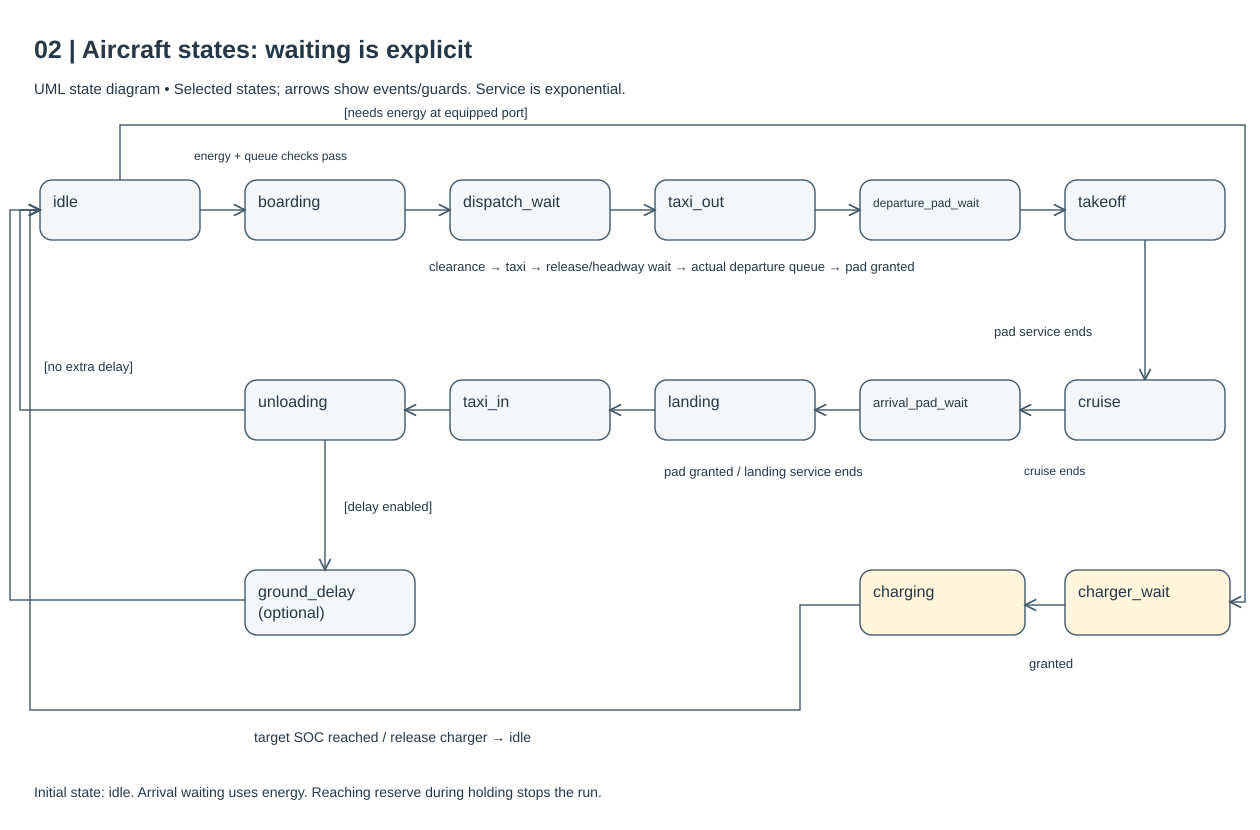

In [4]:
display(SVG(filename='uml/02_aircraft_states.svg'))

### 4.1 Binary dispatch rule and its interpretation
For route $i\to j$, let $s$ denote current SOC, $r$ the reserve, $e_{ij}$ the nominal mission energy divided by battery capacity, and $m$ the planned mission margin. At port $j$, at most $K_j-1$ jobs can precede an admitted aircraft in the FIFO pad queue. Their exponential service times, including the memoryless residual of a job in service, give the conservative stochastic envelope
$$H_j=F^{-1}_{\mathrm{Erlang}(K_j-1,\,\mathrm{scale}=1/\mu_j)}(q),$$
with $H_j=0$ when $K_j=1$. This needs the exponential-service and FIFO assumptions; it does **not** require Poisson aircraft arrivals.

The planned leg budget is
$$b_{ij}=(1+m)e_{ij}+\frac{P_h H_j}{60E_0}.$$
The least-budget directed recovery route from $j$ to a charger has cost $g(j)$, zero at a charging port. A current flight has sufficient planned energy when
$$s\geq b_{ij}+g(j)+r.$$
`Simulation._paths()` finds $g$ by Bellman relaxation over the directed network. `SafetyPolicy.assess()` combines this condition with a forecast charger wait no greater than `max_charger_wait_min`. Existing stand and pad-permit constraints must also pass before assignment. Rejected candidates remain on the ground; the scheduler may charge them or choose another aircraft.

At K=4, mean service 1 min and q=0.99, $H\approx8.406$ min. With 30 kW holding and 100 kWh capacity, the allowance is 4.203 kWh. A 30 km mission uses 20 kWh; with the 10% planning margin its leg budget is 26.203 kWh. Landing at a charger requires 41.203% initial SOC including 15% reserve. Landing at a port requiring one further 30 km leg to charging requires 67.406%.

A charger queue limit is an **operational acceptance condition**, not a claim that an aircraft powered down on the ground becomes unsafe after a fixed number of minutes. Next nominal service feasibility is reported separately. The future aircraft assignment remains flexible.

The quantity q is not a fitted safety probability. Even for a fixed path with $J$ landings, q is per landing; a union bound gives at most $J(1-q)$ probability of at least one allowance exceedance under the model, not a calibrated accident probability. Extra SOC and the mission margin mean an allowance exceedance need not reach reserve. No finite battery can guarantee survival of every unbounded exponential wait.

References: [SciPy Erlang quantiles](https://docs.scipy.org/doc/scipy-1.16.2/reference/generated/scipy.stats.erlang.html), [SimPy resource queue semantics](https://simpy.readthedocs.io/en/stable/api_reference/simpy.resources.html). The energy-planning motivation is consistent with considering planned flights and deviations in [EU Regulation 2024/1111, UAM.OP.VCA.191](https://eur-lex.europa.eu/eli/reg_impl/2024/1111/oj/eng/pdf); this is an EU contextual reference, not an implemented UK compliance rule or the source of the numerical parameters.

## 5. Run the 1, 3 and 5-minute separation comparisons
These intervals mean minimum following separation along the same directed route at constant cruise speed. They do not force a flight every 1, 3 or 5 minutes. Opposite directions and other routes are assumed independent; crossing conflicts are not modelled.

The timetable offers a service every 30 minutes per directed route. Its scheduled time is a **not-before departure target**. For a simple conservative rule, an aircraft joins the takeoff queue no earlier than that time and the previous actual same-route departure plus headway. Actual departure is at the end of pad service, so queueing/service can delay it further. One pending departure per route prevents an overtaking departure.

An arrival permit secures space, not an exact landing time. A passenger journey completes only after landing, taxi-in and unloading.

In [5]:
headway_sims = [Simulation(replace(config, headway_min=h)).run() for h in (1, 3, 5)]
for sim in headway_sims: audit(sim)
baseline = headway_sims[1]
table([dict(headway_min=s.config.headway_min, **measurements(s)) for s in headway_sims],
      ['headway_min','arrivals','completed','not_completed','flights','reposition_flights',
       'served_fraction','timely_fraction','p95_wait_min'])

headway_min,arrivals,completed,not_completed,flights,reposition_flights,served_fraction,timely_fraction,p95_wait_min
1,362,357,5,161,19,0.986,0.743,110.110
3,362,357,5,161,19,0.986,0.743,110.110
5,362,357,5,161,19,0.986,0.743,110.110


## 6. Flying/charging time and actual queue plots
The stacked bars sum to 100% of fleet time. Cruise, takeoff and landing form the reported flying fraction; arrival pad waiting (abstract airborne holding) is shown separately. Charging excludes waiting for a charger. The other states account for all remaining aircraft time.

The trace separates passengers awaiting boarding, aircraft waiting for a charger, actual aircraft at pad queues N, and future permits R. Different populations must not be added as one queue. In the aircraft queue chart, an aircraft's wait begins when it physically joins the pad queue, not when the controller reserves permission. N includes one in service; max(N−1,0) is the waiting count.

Pad busy time divided by observation time gives utilisation. Charger utilisation divides by installed charger time; zero chargers is displayed as zero. The resource plot deliberately draws mean actual N and mean R as separate bars. The controller conservatively limits N+R≤K.

Demand stops after 10 hours; the next two hours provide extra observation. A shrinking passenger queue during this period does not prove stability under continuing demand. Queue wait statistics report unfinished aircraft too; completed waits alone can be biased.

In this default example the 1/3/5-minute bars are almost identical because the timetable and aircraft turnaround usually produce larger gaps already. A minimum headway can be inactive; that is different from forcing departures at that frequency.

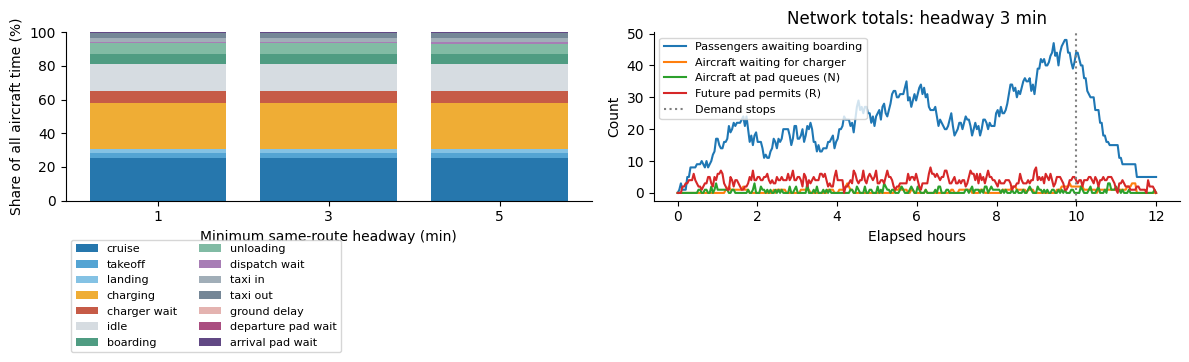

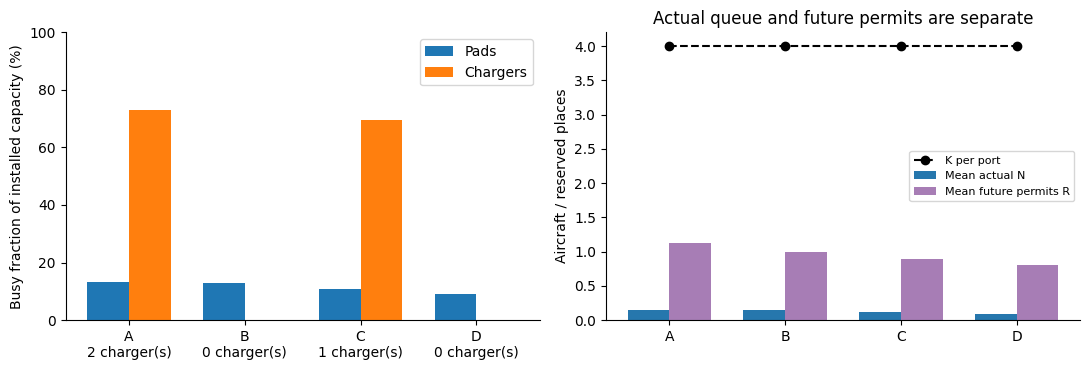

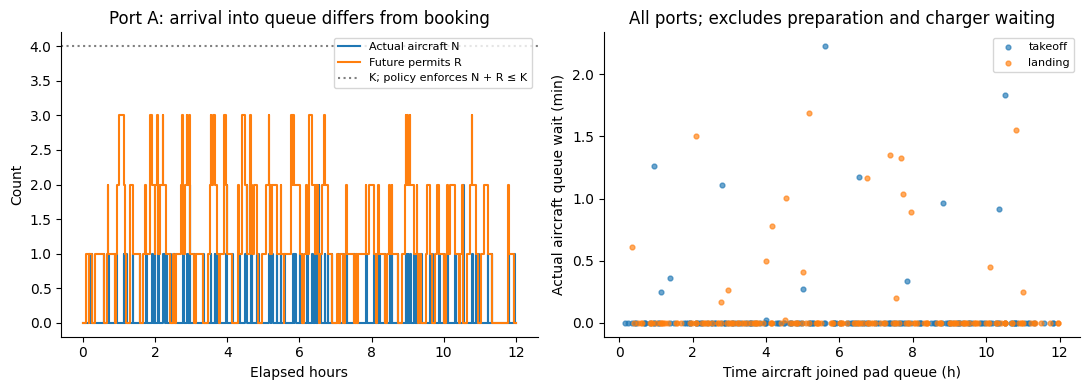

port,K,L,Lq,Wq,busy,mean_reservations,not_started,not_completed
A,4,0.143,0.011,0.085,0.132,1.121,0,0
B,4,0.146,0.016,0.133,0.129,0.994,0,0
C,4,0.115,0.006,0.062,0.109,0.893,0,0
D,4,0.093,0.002,0.022,0.091,0.797,0,0


In [6]:
plots.time_and_queues(headway_sims)
plots.resources(baseline)
plots.aircraft_queues(baseline)
table([dict(port=p, **v.queue.statistics(0,baseline.env.now)) for p,v in baseline.ports.items()],
      ["port","K","L","Lq","Wq","busy","mean_reservations","not_started","not_completed"])

## 7. Aircraft rotations and changing the network
Each row of the rotation plot is one aircraft. Blue cruise blocks carry route labels: the same row can show A→B then B→C. Orange means charging; red means waiting for a charger. Battery traces are for three example aircraft and include actual holding losses and the illustrative reserve.

Changing the number of ports does not require new model classes. Custom route, demand, initial-placement and override dictionaries must use the configured port names. The example factory automatically filters its default port overrides; the model rejects inconsistent custom inputs with an explanation.

Three ports and five aircraft ran using exactly the same classes.


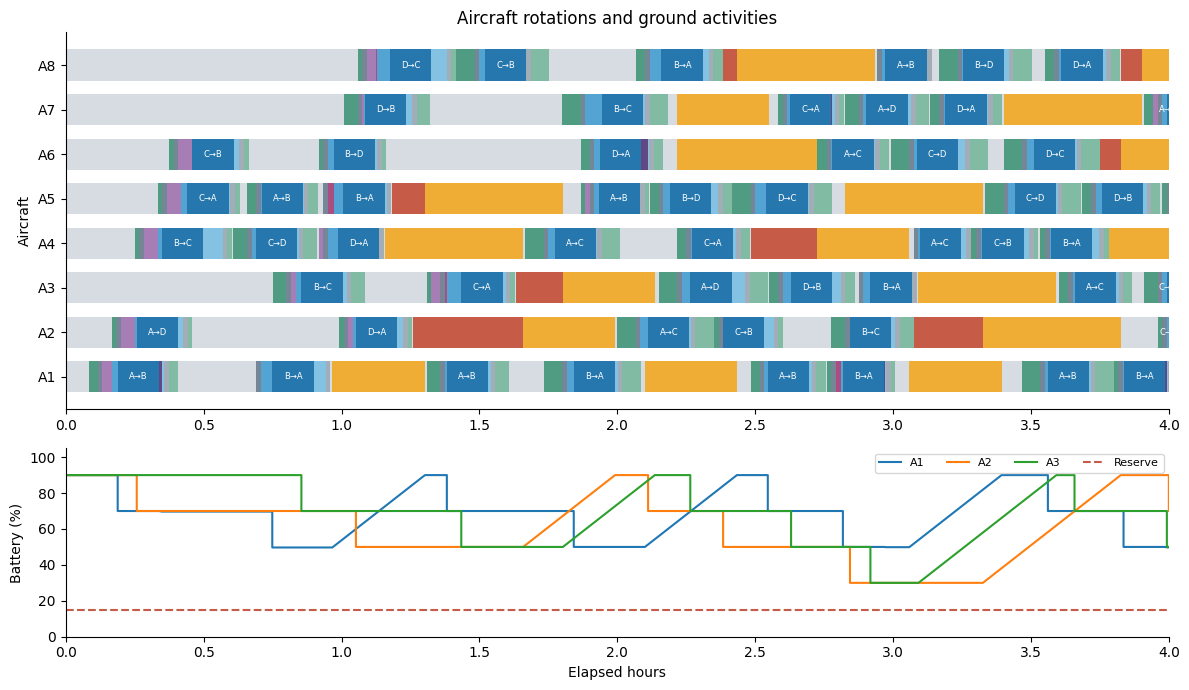

arrivals,completed,flights,not_completed
76,70,26,6


In [7]:
plots.rotation(baseline)
three_port_config = example_config(port_names=('A','B','C'), fleet=5,
                                   horizon_min=180, demand_stop_min=120)
three_port_sim = Simulation(three_port_config).run()
audit(three_port_sim)
table([measurements(three_port_sim)], ['arrivals','completed','flights','not_completed'])
print('Three ports and five aircraft ran using exactly the same classes.')

### 7.1 Energy decisions and charging forecasts
The first safety panel gives the battery margin **above the complete dispatch budget**, including reserve and recovery. Zero is the acceptance boundary; this is not a battery percentage plot. The second panel counts approved assignments by forecast charger wait; the dashed line is the operational limit. Rejected assignments are reported separately in the table, so accepted flights alone cannot establish service capacity.

The third panel compares observed landing queue waits with each port's planning allowance. A wait above its allowance is a tail event; it is not automatically reserve exhaustion. Missing unfinished waits remain censored. The energy ledger and the failure count identify whether reserve was reached. The battery rotation figure includes actual holding losses, rather than subtracting a planned allowance regardless of what happened.

The decision table gives a few committed services, their required/available SOC, intended charging port and next nominal-service forecast. A false nominal-feasibility value indicates a possible need for a later aircraft substitution, delay or cancellation; it is not permission to violate the energy gate.

Recorded rejection reasons: {'insufficient energy': 16, 'charging queue forecast exceeds limit': 6}


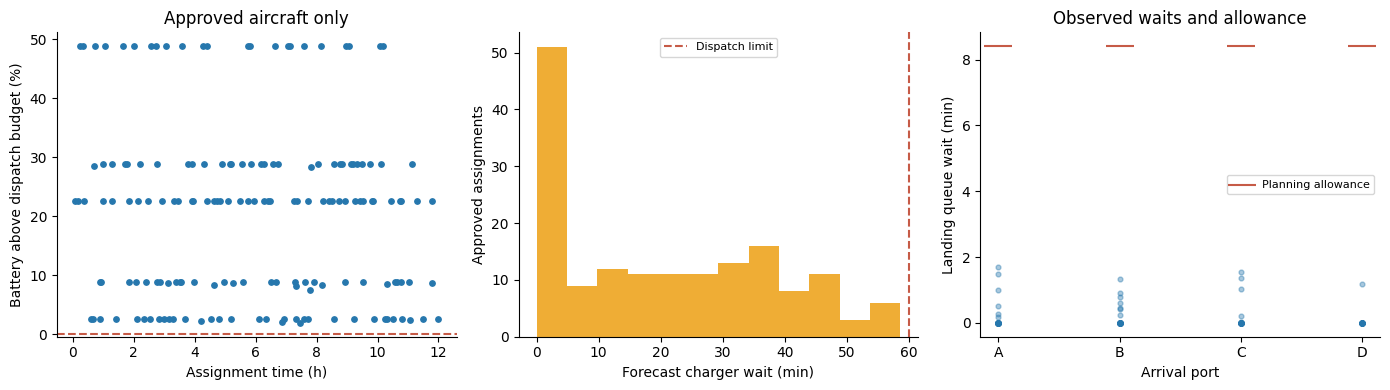

dispatches_approved,rejected_candidate_pairs,rejected_service_flights,minimum_soc,holding_kwh,holding_allowance_exceedances,safety_failures,nominal_rotation_conflicts
161,22,19,0.287,7.589,0,0,143


flight,aircraft,soc,required_soc,margin_soc,charger,charger_wait_min,next_nominal_flight,next_nominal_feasible
F1,A1,0.900,0.674,0.226,A,0.000,F6,False
F3,A2,0.900,0.674,0.226,A,0.000,F9,False
F5,A4,0.900,0.412,0.488,C,0.000,F19,True
F7,A5,0.900,0.412,0.488,A,33.609,F14,True
F8,A6,0.900,0.674,0.226,A,13.703,F16,True
F9,A4,0.700,0.674,0.026,A,0.000,F19,False
F13,A5,0.700,0.674,0.026,A,10.203,F14,False
R284_B,A1,0.697,0.412,0.285,A,58.609,F21,False


In [8]:
plots.safety_summary(baseline)
safety_metrics = measurements(baseline)
table([safety_metrics], ['dispatches_approved','rejected_candidate_pairs','rejected_service_flights',
    'minimum_soc','holding_kwh','holding_allowance_exceedances','safety_failures','nominal_rotation_conflicts'])
print('Recorded rejection reasons:', safety_metrics['safety_rejection_reasons'])
table([d for d in baseline.log.safety_checks if d['committed']][:8],
    ['flight','aircraft','soc','required_soc','margin_soc','charger','charger_wait_min',
     'next_nominal_flight','next_nominal_feasible'])

## 8. Centralised scheduling, aircraft swapping and UML
The controller knows present aircraft locations/charge, passenger queues, timetable, stands, chargers, actual pad occupancy and future permits. It never reads future random arrival or service samples.

1. Find the oldest services approaching their scheduled time. A pending service expires after `max_assignment_delay_min`; its passengers remain waiting. Empty services are cancelled at their target time.
2. Charge aircraft needing energy. For each candidate service, select an idle aircraft at its origin that passes `SafetyPolicy.assess`: sufficient battery for mission, holding allowance, recovery to charging and reserve, plus a forecast charging wait within the configured limit. Prefer its nominal aircraft; if unavailable, assign another ready aircraft. For example, A1 still flying or charging can be replaced by ready A2. Once committed, the aircraft is not swapped mid-boarding or mid-flight.
3. If needed, reposition an empty aircraft towards demand or a charger. An aircraft may subsequently fly A→B→C→D; it is not tied to A↔B.
4. Find a chain ending at a free destination stand, or a cycle that releases full stands together. Reserve a departure permit and an arrival permit for every flight in that batch. If N+R+new permits would exceed K, defer the whole batch on the ground and retry.
5. Assign seats, board, and exchange stand claims atomically at pushback. A claim includes an inbound aircraft. The controller waits for this batch's boarding before assigning another batch. Safety forecasts are refreshed sequentially within a batch, so its earlier tentative commitments contribute to the charger workload forecast.
6. Aircraft enter the real queues when they reach them. A permit converts to actual occupancy; independent exponential service determines completion. The next route becomes eligible after actual departure. After landing/unloading/any extra ground delay, the aircraft becomes available again.

The deadline controls assignment, **not** an upper bound on random departure delay. The 0.5-minute controller tick does not turn SimPy into a fixed-step simulator. This is a simple scheduling heuristic, not an optimal airline scheduler. K=1 can block a full-stand swap because both departure and future landing need permits; this is a conservative policy limitation, not instability of a finite M/M/1/K queue.

The class, aircraft state and dispatch sequence UMLs below correspond to this code. Editable `.drawio` files open at [diagrams.net](https://app.diagrams.net/); SVG copies require no installation.

Future preferred-aircraft rotations are advisory. Each accepted assignment records whether its next nominal service appears feasible after travel and, when needed, charging. A conflict is not a reason to invent extra energy or force the aircraft onto that service: actual later assignment uses the same safety checks and may substitute a different aircraft, delay or cancel. A timetable slot is not a firm multileg aircraft commitment. The policy uses a receding decision horizon: current leg plus a complete energy-feasible recovery path to charging, then reassessment at the next assignment.

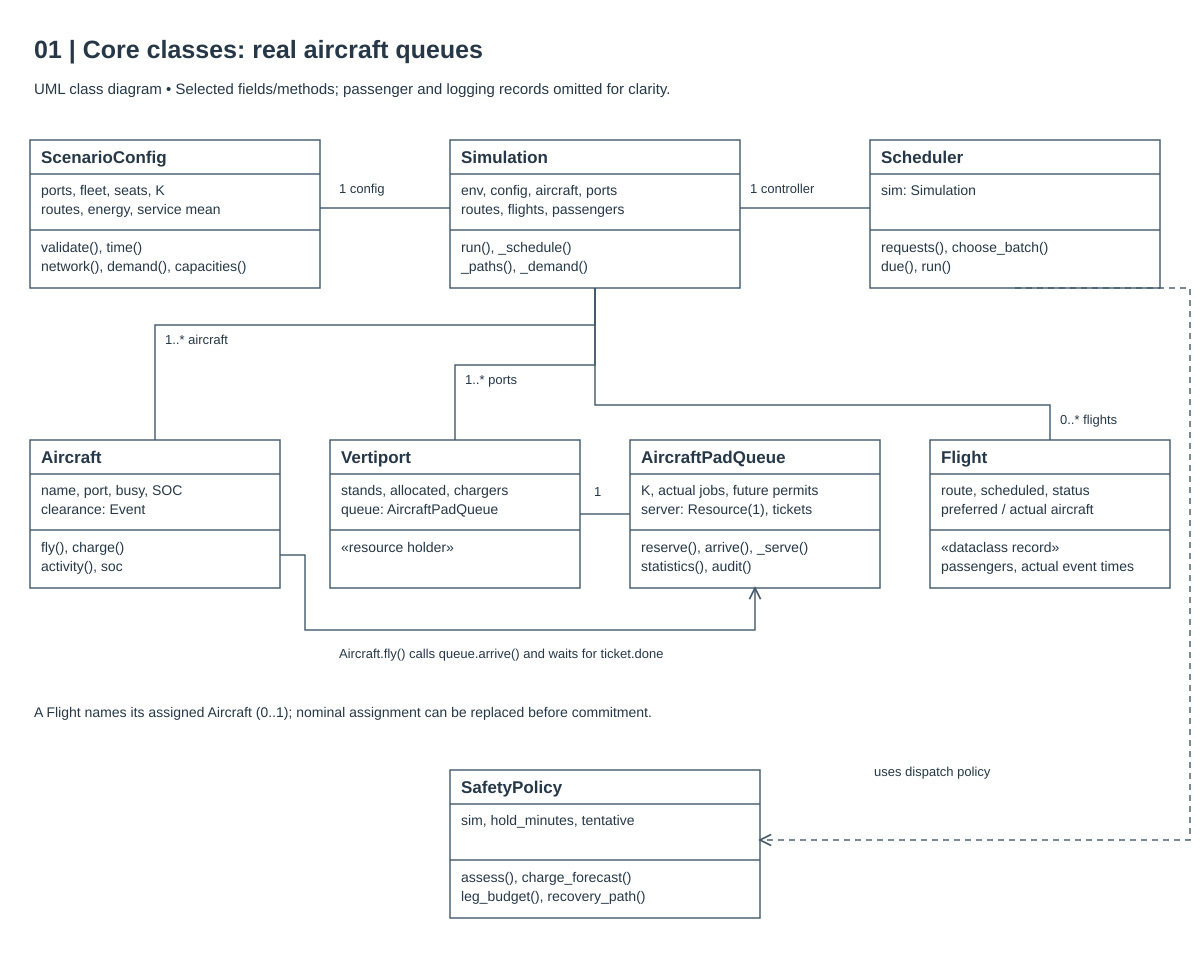

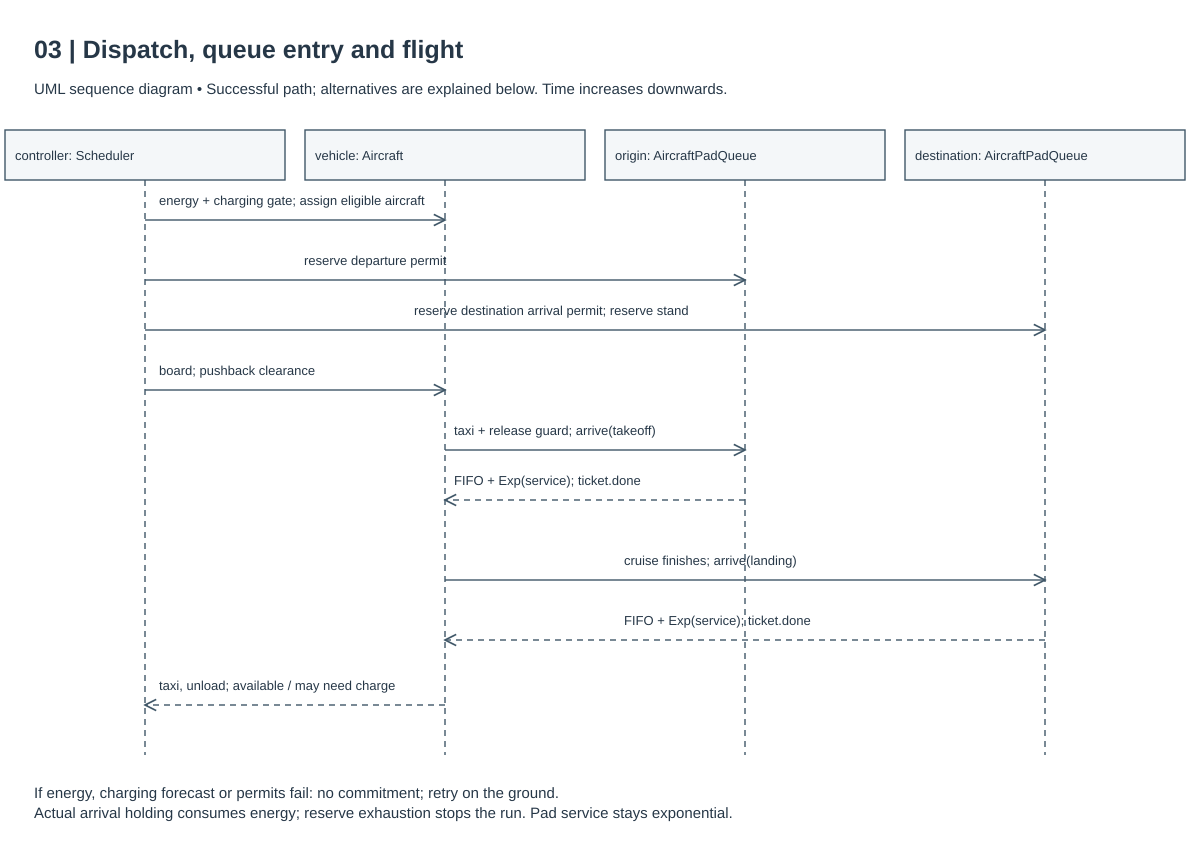

flight,route,nominal,actual,scheduled_min,departed_min
F1,A→B,A1,A1,10.000,11.317
F3,A→D,None,A2,15.000,15.468
F5,B→C,A4,A4,20.000,20.924
F7,C→A,A5,A5,25.000,26.485
F8,C→B,A6,A6,27.500,27.525
F9,C→D,A2,A4,30.000,41.423
F13,A→B,A3,A5,40.000,42.621
F17,B→C,A8,A3,50.000,51.276
F18,B→D,A3,A6,52.500,58.266
F19,C→A,A4,A3,55.000,86.052


In [9]:
display(SVG(filename='uml/01_classes.svg'))
display(SVG(filename='uml/03_dispatch_sequence.svg'))
table([dict(flight=f.name, route=f.route.origin+'→'+f.route.dest,
            nominal=f.preferred_aircraft, actual=f.aircraft,
            scheduled_min=float(f.scheduled)*config.time_scale_min,
            departed_min=float(f.departed)*config.time_scale_min)
       for f in baseline.flights if f.kind=='service' and f.departed is not None][:12],
      ['flight','route','nominal','actual','scheduled_min','departed_min'])

## 9. Finite horizons, censoring and operational failure
An infinite simulation cannot finish. Use finite horizons, define a failure criterion and extend the run if necessary. Here passengers arrive for 10 hours and are observed for 12; service remains available during the final two hours. We explicitly count unassigned, assigned-but-not-departed, in-transit and completed passengers.

Capacity means meeting chosen service targets under a stated demand distribution and timetable. A bounded pad queue alone does not establish service quality: passengers may accumulate outside it. Not serving somebody by the end is **unserved within the observation horizon**, not necessarily permanent rejection. Mean/p95 waits among departed passengers are conditional and can look deceptively good when many others are still waiting; therefore use the all-arrivals timely fraction alongside them.

The next run extends continuing demand to 24 hours and observation to 26. The early/middle/late passenger cohorts below are all followed to the same run end. They have different available follow-up time, so compare censored counts as well as completed waits. These results diagnose behaviour; they do not prove stationarity or infinite-horizon stability.

A recorded energy failure terminates a run early. `observed_minutes` is then the actual stopped horizon, not the planned horizon. Such a run automatically fails the capacity criteria even if its passenger fractions happen to be high. A stopped failure run cannot resume; a new scenario is required.

In [10]:
long_config = replace(config, demand_stop_min=1440, horizon_min=1560)
long_sim = Simulation(long_config).run()
audit(long_sim)
table([dict(arrival_window=f'{a/60:g}–{b/60:g} h', **measurements(long_sim,a,b))
       for a,b in [(0,240),(600,840),(1200,1440)]],
      ['arrival_window','arrivals','completed','not_completed','timely_fraction','p95_wait_min'])

arrival_window,arrivals,completed,not_completed,timely_fraction,p95_wait_min
0–4 h,130,130,0,0.862,85.155
10–14 h,131,131,0,0.611,310.787
20–24 h,124,117,7,0.758,228.841


## 10. M/M/1/K: mathematics, proof and boundary conditions
Under the **exact local reference assumptions**, $N(t)$ counts aircraft waiting for or using one pad. $K$ is the total capacity; $K-1$ is the maximum waiting count. Offered arrivals are Poisson with rate $\lambda$, service times independent exponential with rate $\mu$, there is one FIFO server, and arrivals seeing $N=K$ are rejected. The controlled harness sends independent aircraft-operation offers into the same `AircraftPadQueue` class, without routing, permits or retries. The operational model retains all those mechanisms.

For small $\Delta t$, one arrival has probability $\lambda\Delta t+o(\Delta t)$, a service completion when busy has probability $\mu\Delta t+o(\Delta t)$, and multiple events have probability $o(\Delta t)$. In particular,
$$P_0(t+\Delta t)=P_0(t)(1-\lambda\Delta t)+P_1(t)\mu\Delta t+o(\Delta t).$$
Subtract $P_0(t)$, divide by $\Delta t$ and take the limit:
$$P'_0(t)=-\lambda P_0(t)+\mu P_1(t),$$
$$P'_n(t)=\lambda P_{n-1}(t)-(\lambda+\mu)P_n(t)+\mu P_{n+1}(t),\quad 1\leq n<K,$$
$$P'_K(t)=\lambda P_{K-1}(t)-\mu P_K(t).$$
Notice the **minus sign** on the empty-state outflow. Rejected arrivals at K do not change the state. Constant rates are time-homogeneous settings; the distribution can still change during the transient.

At stationarity derivatives vanish. The first equation gives $\lambda p_0=\mu p_1$; substituting recursively into the interior equations gives $\lambda p_n=\mu p_{n+1}$. Therefore, with $\rho=\lambda/\mu$,
$$p_n=p_0\rho^n,\qquad p_0=\left(\sum_{j=0}^{K}\rho^j\right)^{-1}.$$
This finite sum also handles $\rho=1$, when $p_n=1/(K+1)$. With positive rates the finite chain has a stationary distribution even at $\rho\geq1$. The infinite M/M/1 requirement $\lambda<\mu$ is not required here; overload appears as blocking.

Poisson arrivals see time-average states (PASTA), so blocking probability is $p_K$. Effective admitted throughput is
$$\lambda_{\mathrm{eff}}=\lambda(1-p_K)=\mu(1-p_0).$$
Then
$$L=\sum_{n=0}^K np_n,\quad L_q=\sum_{n=0}^K\max(n-1,0)p_n=L-(1-p_0),$$
$$W_q=L_q/\lambda_{\mathrm{eff}},\qquad W=L/\lambda_{\mathrm{eff}}=W_q+1/\mu.$$
This is Little's law for **admitted** jobs, not the offered rate. $W_q$ excludes service; $W$ includes it. $\rho$ is offered intensity; actual server utilisation is $1-p_0$, generally not $\rho$.

For $K=4$ and $\lambda=\mu=1$/min: $p_n=0.2$, $\lambda_{eff}=0.8$/min, $L=2$, $L_q=1.2$, $W_q=1.5$ min and $W=2.5$ min.

Primary reference: [MIT, M/M/1/K finite queues](https://web.mit.edu/urban_or_book/www/book/chapter4/4.6.3.html). This extends the earlier [Constantin queueing notes](https://www.math.uchicago.edu/~may/VIGRE/VIGRE2011/REUPapers/Constantin.pdf); the boundary at K and the admitted throughput are the essential changes.

rho,K,pn,blocking,busy,effective_rate,L,Lq,Wq,W
1.000,4,"[0.2, 0.2, 0.2, 0.2, 0.2]",0.200,0.800,0.800,2.000,1.200,1.500,2.500


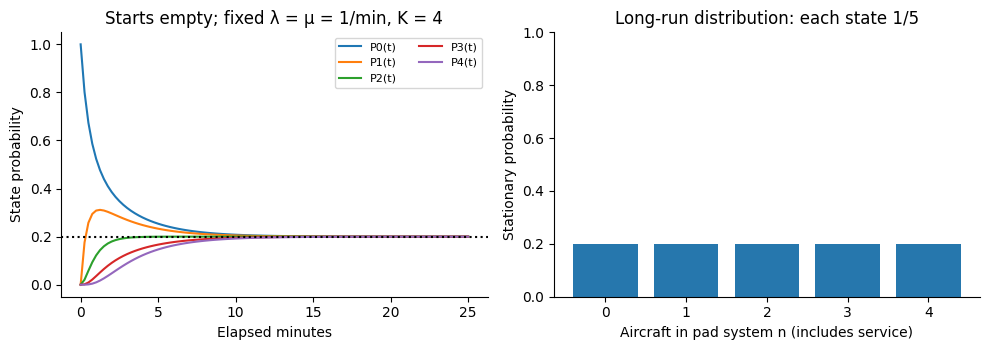

In [11]:
exact = theory(arrival_rate=1, service_rate=1, K=4)
table([exact], ['rho','K','pn','blocking','busy','effective_rate','L','Lq','Wq','W'])
plots.transient_plot()

The transient plot starts empty. Fixed rates do not imply a stationary initial distribution. `transient()` builds the finite-chain generator Q and computes the first row of exp(Q t).

**What transfers to the operating model:** one shared pad, exponential service, FIFO, actual aircraft occupancy and finite capacity. **What is approximate:** the first M (independent Poisson aircraft arrivals). Passenger arrivals being Poisson does not make aircraft arrivals Poisson: batching seats, a finite fleet, timetable, headways and charging create dependence. In addition, future permits R restrict admissions when N<K, and deferred flights retry. Therefore N alone need not be Markov, arrival-seen blocking need not equal time-full fraction, and exact Wq/PASTA formulas are not guarantees for this network.

We measure operational aircraft Wq directly. Theoretical λ counts offered aircraft operations/minute (takeoffs plus landings), not passengers/minute. μ is inverse mean pad service. The Poisson harness verifies the very same queue code under the assumptions that make the formulas exact. No independent replacement flight model is being substituted. See `MODEL_AND_MATH.txt` for the full proof and approximation boundary.

The energy gate further couples aircraft arrivals to their operating history. It does not turn aircraft input into Poisson input. Pad service is still independent exponential and is not truncated by the planning percentile. The controlled M/M/1/K harness has no aircraft energy state and is therefore unchanged mathematically.

## 11. How the Python code actually runs
`Simulation(config)` creates the SimPy clock, ports, routes, aircraft, passengers' arrival processes and scheduled flights, then starts `Scheduler.run()`. Calling `.run()` advances events. A Python generator suspends at `yield`; another process can run until that event completes. This is not an operating-system thread per aircraft.

| File / class | Purpose and key methods |
|---|---|
| `model.py`: ScenarioConfig | Physical editable inputs; `validate`, `time`, `network`, `capacities`, `demand` |
| Route / Passenger / Flight | `@dataclass` records; a flight and an aircraft are different objects |
| Aircraft | `fly`, `charge`, `soc`, `activity`; keeps energy and location across trips |
| Vertiport | Stands, charger Resource and its real `AircraftPadQueue` |
| Scheduler | `due`, `requests`, `choose_batch`, `run`; assignment and substitutions |
| Simulation / Recorder | Connect processes; retain event/state histories |
| `queues.py`: AircraftPadQueue | `reserve` creates future permission; `arrive` converts it into a real aircraft ticket; `_serve` requests FIFO Resource and samples exponential time |
| Ticket | Aircraft identity, flight identity, operation, arrival/start/end, and completion Event |
| `safety.py`: SafetyPolicy | `leg_budget`, `recovery_path`, `charge_forecast`, `assess`, `record`; binary decisions and auditable reasons |
| `results.py` | Measured minutes, fractions, aircraft queue Wq and independent audits |
| `mm1k.py` | `theory`, `transient`, `simulate`: equations and Poisson test harness using the same AircraftPadQueue |
| `experiments.py` | Repeated demand/fleet/K/delay trials, uncertainty and saved-result checks |
| `plots.py` | Figures only; does not schedule flights |

`replace(config, fleet=5)` creates a changed scenario. Each simulation owns its state; no mutable global aircraft lists. Demand, per-port pad service and per-aircraft extra delays use separate random generators. Changing fleet preserves passenger arrival times for a paired seed. Changing the reference units preserves physical results.

`CODE_GUIDE.txt` contains the method-by-method description; `SAFETY_EXPLANATION.tex` is a standalone Overleaf report of the extension. Real aircraft queue ticket records carry actual aircraft/flight identifiers, making the service path inspectable.

## 12. Validate mechanisms before interpreting results
The tests use hand-checkable trips and invariants: timestamps, seat limits, unique passenger assignment, correct destination, simultaneous stand swaps, pad separation, actual finite aircraft queues, future-permit separation, FIFO landing/takeoff service, charger capacity, battery balance, depleted aircraft recovery, multiple-port rotations, aircraft substitutions, unit changes and stale-cache rejection.

Passing these tests is **verification of this implementation**, not validation against real operations. The latter requires measured demand, repeated-mission energy and charge curves, handling distributions and field observations.

The safety tests additionally check a multileg recovery budget, charging workload with one/two chargers, low-energy rejection, charger-congestion rejection, swapping a charging aircraft, actual and partially observed holding energy, unit invariance, and an intentionally extreme delay that must stop at reserve. Passing those tests verifies code behaviour, not aircraft performance in service.

In [12]:
suite = unittest.defaultTestLoader.discover('.', pattern='test_*.py')
test_output = io.StringIO()
test_result = unittest.TextTestRunner(stream=test_output, verbosity=1).run(suite)
print(test_output.getvalue())
assert test_result.wasSuccessful()
print('Baseline conservation/resource audit:', audit(baseline))

...............................................
----------------------------------------------------------------------
Ran 47 tests in 5.979s

OK

Baseline conservation/resource audit: True


### 12.1 Deliberate adverse-case demonstration
This controlled fixture holds B's pad busy for 200 minutes to exercise the protection. It is a test input, not a sample estimate of normal operating risk. A1 departs only after passing the original dispatch check, later encounters the extreme landing wait, and the run stops when its SOC reaches 15%. The distinction between **ex ante approval** and **realised outcome** is essential with unbounded random delays. There is no weather or structural-damage variable mixed into this measure.

In [13]:
from test_safety import holding_example
stress = holding_example(service_minutes=200, until=250)
assert stress.failure_event.triggered and audit(stress)
table([measurements(stress)], ['observed_minutes','minimum_soc','holding_kwh',
    'safety_failures','stopped_for_safety','passes_targets'])
table(stress.log.failures, ['time_min','aircraft','flight','reason'])

observed_minutes,minimum_soc,holding_kwh,safety_failures,stopped_for_safety,passes_targets
130.000,0.150,55.000,1,True,False


time_min,aircraft,flight,reason
130.000,A1,F1,holding reached protected reserve


## 13. Repeated M/M/1/K experiments versus theory
The saved experiments use six independent replications per (ρ,K) pair, with 12,000 minutes simulated and the first 1,200 excluded from occupancy/rate measurements. Waits are for customers admitted during the measured interval; admitted customers are followed to completion after the source stops. Occupancy and throughput still use the original measurement window.

The error bars are 95% Student-t intervals across replication means, not across individual dependent customers. Nominal 95% intervals will not all contain theory; inspect the size and pattern of discrepancies. A fixed warm-up is a study choice, not a universal guarantee. The saved grid uses ρ=0.5,1,1.5 and K=1,4,8.

`RUN_EXPERIMENTS=False` uses checked saved results. Change it to `True` after modifying the configuration or model. A fingerprint prevents old results being silently presented as results of new code. Recomputing may take several minutes. Confidence interval reference: [NIST](https://www.itl.nist.gov/div898/handbook/eda/section3/eda352.htm).

These trials exercise the exact same pad service implementation used by real flights. They verify the queue mechanism under controlled Poisson input; they do not establish Poisson arrivals or validate the real-world operating network.

Network replications: 90
M/M/1/K replications: 54


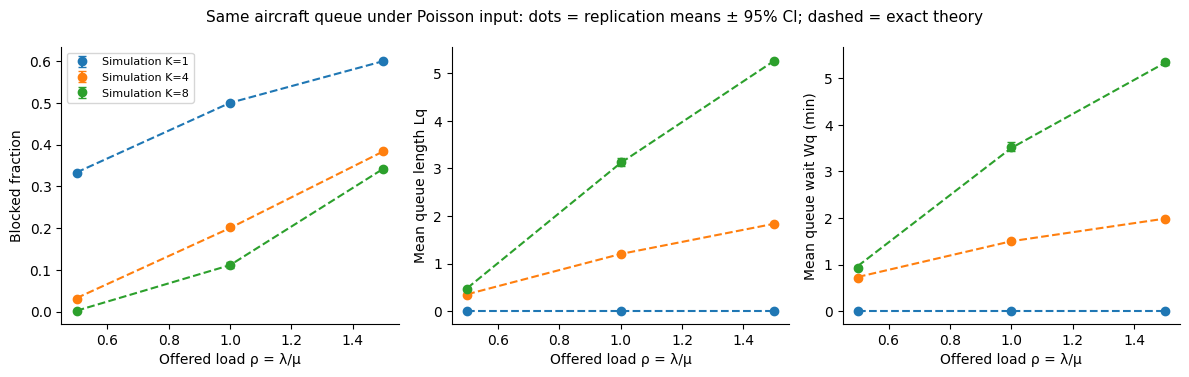

In [14]:
RUN_EXPERIMENTS = False
if RUN_EXPERIMENTS:
    experiment_data = run_all(config)
    save_results(experiment_data, 'experiment_results.json')
else:
    experiment_data = load_results('experiment_results.json', config)
print('Network replications:', len(experiment_data['network_runs']))
print('M/M/1/K replications:', len(experiment_data['benchmark_runs']))
plots.benchmark(experiment_data)

## 14. The two full-capacity experiments
**Demand sweep:** hold fleet, seats, timetable, resources and policy fixed; increase total offered passenger demand while preserving route shares. **Fleet sweep:** hold passenger demand, seats, timetable and resources fixed; reduce the aircraft fleet and redistribute starting aircraft automatically. Paired seeds give identical passenger arrivals across fleet sizes. Five seeds estimate variability; more seeds and narrower levels are needed near any final operating threshold.

The top panels show the fraction completing and the fraction departing within the waiting-time target, both divided by **all arrivals**. The bottom panels show occupied-seat fraction. A high load factor can coexist with bad waits and many unserved passengers. Empty repositioning consumes aircraft, energy and pad slots, so we show load factor both with and without those flights.

A level passes the illustrative criteria only if every tested seed meets both thresholds. The maximum passing tested demand and minimum passing tested fleet are reported below, if any. They are conditional on this policy, timetable and finite day; they are not a proven maximum, a profit optimum or a guarantee for unseen demand. If none pass, the honest result is that the tested levels did not establish a suitable operating point.

{
  "demand": {
    "passing_levels": [],
    "best_tested": null
  },
  "fleet": {
    "passing_levels": [],
    "best_tested": null
  }
}


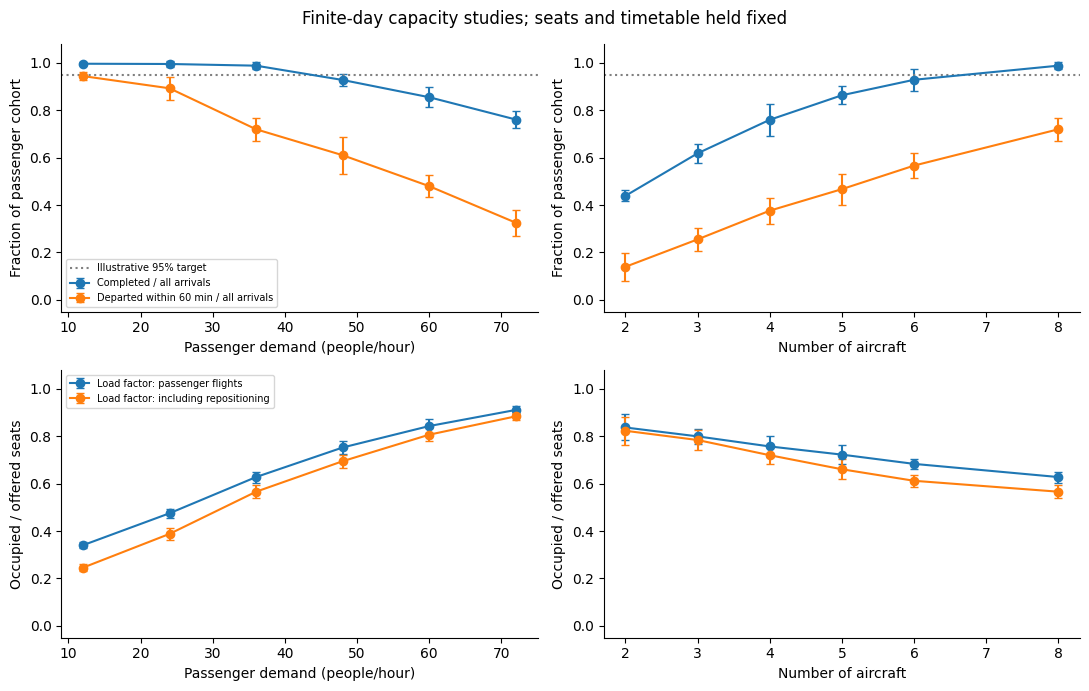

group,level,completed_mean,timely_mean
demand,12,0.997,0.945
demand,24,0.996,0.893
demand,36,0.989,0.720
demand,48,0.928,0.611
demand,60,0.855,0.480
demand,72,0.761,0.326
fleet,2,0.439,0.140
fleet,3,0.618,0.255
fleet,4,0.760,0.376
fleet,5,0.864,0.467


In [15]:
plots.capacity(experiment_data)
print(json.dumps(experiment_data['capacity'], indent=2))
table([dict(group=g, level=v, completed_mean=interval([r['metrics']['served_fraction'] for r in experiment_data['network_runs'] if r['group']==g and r['level']==v])['mean'],
            timely_mean=interval([r['metrics']['timely_fraction'] for r in experiment_data['network_runs'] if r['group']==g and r['level']==v])['mean'])
       for g in ('demand','fleet') for v in sorted({r['level'] for r in experiment_data['network_runs'] if r['group']==g})],
      ['group','level','completed_mean','timely_mean'])

## 15. K, disruption and passenger information
The K sensitivity changes actual aircraft queue capacity and the associated conservative permit budget while preserving stands. More admission space does not guarantee better service under a particular scheduler: it can commit aircraft early and change their later positions. The disruption sensitivity introduces independent exponential extra ground delays after unloading; the controller learns the realised delay only as time passes and can use another ready aircraft.

The passenger plot uses all arrivals in the denominator. Its height shows what fraction actually departed; any missing mass represents passengers not yet departed. The route-gap plot compares realised gaps with the timetable. It is possible to publish a timetable and still operate irregularly.

The bus analogy distinguishes **service reliability** from **passenger information**. The model generates passengers independently of timetable knowledge. It does not implement passengers who time their arrivals using published or live information. For independent random arrivals and unlimited boarding, renewal theory gives E[wait]=E[H²]/(2E[H]) = E[H]/2 + Var(H)/(2E[H]); irregular headways increase the mean wait at a fixed mean gap. Finite seats, scheduled passenger arrivals and queues invalidate a direct use of that simple formula here. [MIT public transport lecture](https://ocw.mit.edu/courses/1-258j-public-transportation-systems-spring-2017/45747c1e2881ec58cf72b1f4f99474dd_Tsn0xSQjo14.pdf).

Cancelled services by reason: {'no passengers': 86, 'assignment deadline': 55}
Flying / airborne waiting / charging fractions: 0.30915824551572213 0.0026350645898323686 0.269745059747316


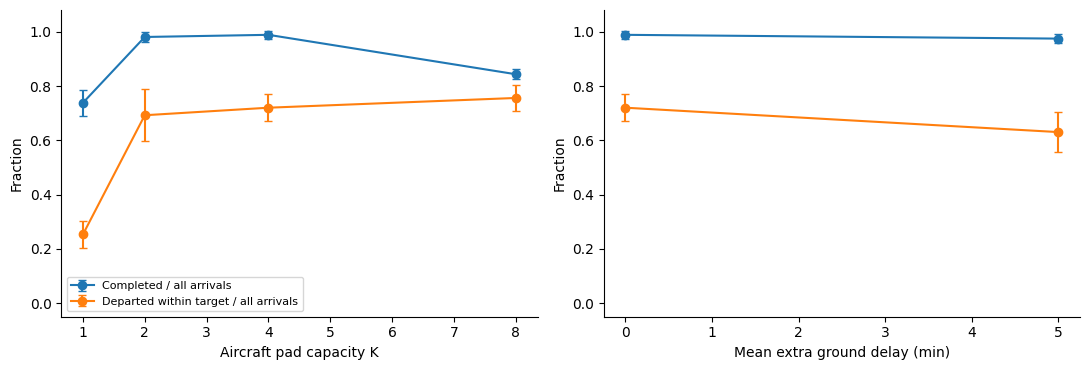

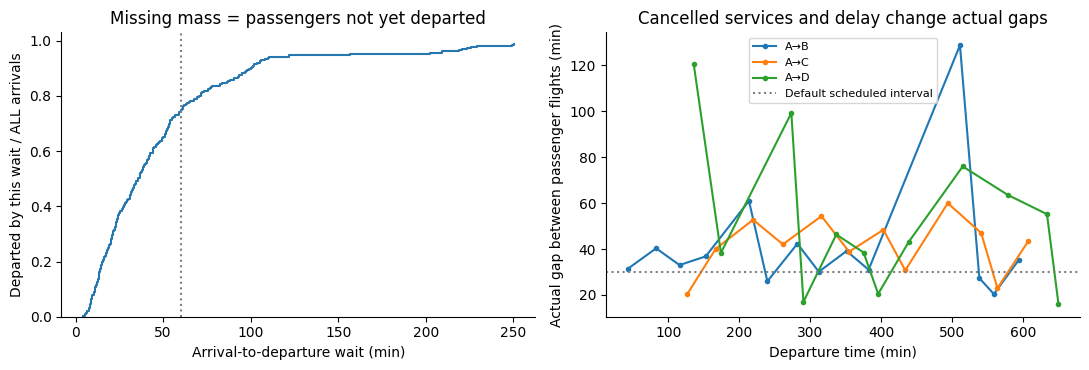

arrivals,completed,unassigned,assigned_not_departed,departed_not_completed,mean_wait_min,p95_wait_min,served_fraction,timely_fraction,reassignments
362,357,1,4,0,47.267,110.110,0.986,0.743,118


aircraft,flight,operation,arrived_min,wait_min
A1,F1,takeoff,10.000,0.000
A2,F3,takeoff,15.000,0.000
A5,F7,landing,35.485,0.000
A5,F13,takeoff,42.500,0.000
A1,R284_B,landing,53.945,0.000
A4,R285_D,landing,68.187,0.000
A5,R286_B,landing,69.389,0.000
A2,F22,landing,72.137,0.000
A1,F25,takeoff,82.500,0.000
A3,F19,landing,95.052,0.000


In [16]:
plots.sensitivity(experiment_data)
plots.reliability(baseline)
r = measurements(baseline)
table([r], ['arrivals','completed','unassigned','assigned_not_departed','departed_not_completed',
            'mean_wait_min','p95_wait_min','served_fraction','timely_fraction','reassignments'])
print('Cancelled services by reason:', r['cancellation_reasons'])
print("Flying / airborne waiting / charging fractions:", r["flying_fraction"], r["airborne_wait_fraction"], r["charging_fraction"])
table([dict(aircraft=t.aircraft, flight=t.flight, operation=t.operation,
            arrived_min=float(t.arrived)*config.time_scale_min,
            wait_min=float(t.started-t.arrived)*config.time_scale_min)
       for t in baseline.ports["A"].queue.tickets[:10] if t.started is not None],
      ["aircraft","flight","operation","arrived_min","wait_min"])

## 16. Established scope and remaining assumptions
The simulator integrates aircraft pad queues, finite reusable aircraft, configurable routes and seats, passenger demand, charging, timetable services, aircraft substitutions, both capacity experiments and a binary energy dispatch policy.

Dispatch approval means the configured energy/charging conditions were met at commitment. The budget includes the current mission, a margin, a landing-wait allowance and a complete recovery path to a charger, ending with reserve. A forecast includes existing charging jobs and earlier committed inbound plans. Future demand, queue ordering on later arrivals, delays and charger failures are not known in advance; the forecast is not a slot reservation. Later assignments are checked afresh. A nominal timetable conflict can be handled by swapping aircraft.

The 99% landing-queue allowance is a per-landing planning quantity under the specified exponential single-server assumptions, not a 99% guarantee for an entire itinerary or operating day. Long tails remain possible and a reserve stop is explicitly recorded. Weather, turbulence, structural damage, battery ageing, charging taper, emergencies, powered ground energy, conflict detection and legal compliance are outside this extension. Holding power and energy parameters are synthetic.

M/M/1/K theory continues to verify the same queue under independent Poisson input. The operational network is not exactly an M/M/1/K chain, and finite-day capacity results are conditional on the scheduler and inputs rather than a proven global optimum.

The notebook imports modules, creates scenarios, runs them and displays measurements. Saved experiments are protected by a configuration/source fingerprint, now including `safety.py`. The executable source and all figures are included in this folder.